# Cassava Leaf Disease Classification | ResNet18, PyTorch

- ResNet18 (pretrained), 5 classes. Each step changes one thing (except v2) and is compared with the previous best version.
- Final model (v7, 384x384): accuracy 0.874, macro-F1 0.772 on my own validation split
  (always predicting the largest class gives 0.615 accuracy).
- Notes under each step: what I changed, what I expected, what happened.
- The notes were written after an earlier run. GPU training is not fully deterministic,
  so numbers in this run may differ slightly (most of all for the short 3-epoch v1).

In [1]:
import os, json, random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = "/kaggle/input/competitions/cassava-leaf-disease-classification"
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "not available")
print("Files in data dir:", sorted(os.listdir(DATA_DIR)))
print("Train images:", len(os.listdir(os.path.join(DATA_DIR, "train_images"))))

GPU: Tesla T4
Files in data dir: ['label_num_to_disease_map.json', 'sample_submission.csv', 'test_images', 'test_tfrecords', 'train.csv', 'train_images', 'train_tfrecords']
Train images: 21397


In [2]:

train_df = pd.read_csv(
    os.path.join(DATA_DIR, "train.csv")
)

print(train_df.head())
print("\nDataset shape:", train_df.shape)

print("\nClass distribution:")
print(train_df["label"].value_counts().sort_index())


         image_id  label
0  1000015157.jpg      0
1  1000201771.jpg      3
2   100042118.jpg      1
3  1000723321.jpg      1
4  1000812911.jpg      3

Dataset shape: (21397, 2)

Class distribution:
label
0     1087
1     2189
2     2386
3    13158
4     2577
Name: count, dtype: int64


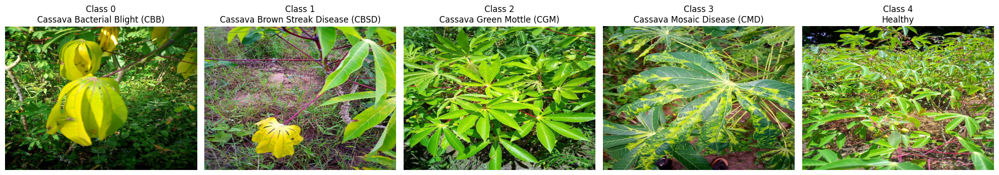

In [3]:

from PIL import Image
import json
import os
import matplotlib.pyplot as plt

# Load class names
with open(
    os.path.join(DATA_DIR, "label_num_to_disease_map.json"),
    "r"
) as f:
    class_names = json.load(f)

# Get the number of classes
num_classes = len(class_names)

# Create a figure with one image per class
fig, axes = plt.subplots(
    1, num_classes,
    figsize=(20, 5)
)

# Select and display one random image from each class
for class_id, ax in enumerate(axes):
    class_samples = train_df[train_df["label"] == class_id]

    sample = class_samples.sample(n=1, random_state=SEED).iloc[0]

    image_path = os.path.join(
        DATA_DIR,
        "train_images",
        sample["image_id"]
    )

    image = Image.open(image_path)

    ax.imshow(image)
    ax.set_title(
        f"Class {class_id}\n{class_names[str(class_id)]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


                                     count  share
disease                                          
Cassava Mosaic Disease (CMD)         13158  0.615
Healthy                               2577  0.120
Cassava Green Mottle (CGM)            2386  0.112
Cassava Brown Streak Disease (CBSD)   2189  0.102
Cassava Bacterial Blight (CBB)        1087  0.051

Majority-class baseline accuracy: 0.615


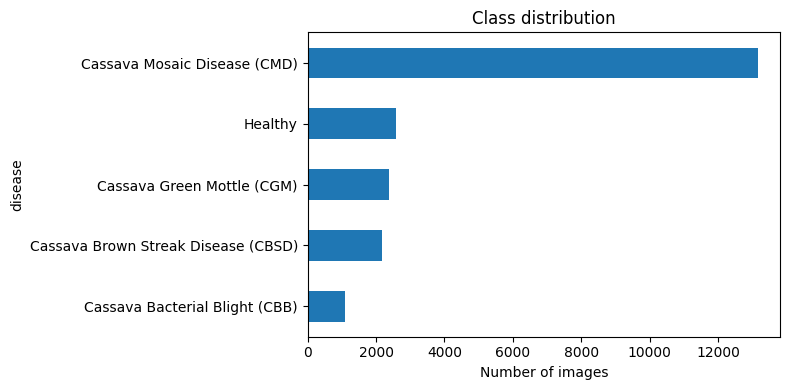

In [4]:
import pandas as pd

# Map numeric labels to disease names for readability
train_df["disease"] = train_df["label"].astype(str).map(class_names)

# Absolute and relative class counts
class_counts = train_df["disease"].value_counts()
class_share = train_df["disease"].value_counts(normalize=True).round(3)
print(pd.DataFrame({"count": class_counts, "share": class_share}))

# Accuracy of a "model" that always predicts the most frequent class
print(f"\nMajority-class baseline accuracy: {class_share.max():.3f}")

# Bar plot of class distribution
class_counts.plot(kind="barh", figsize=(8, 4), title="Class distribution")
plt.xlabel("Number of images")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [5]:
# Check ALL images (Image.open is lazy, so this is reasonably fast)
all_sizes = pd.Series([
    Image.open(os.path.join(DATA_DIR, "train_images", img_id)).size
    for img_id in train_df["image_id"]
])
print(all_sizes.value_counts())

(800, 600)    21397
Name: count, dtype: int64


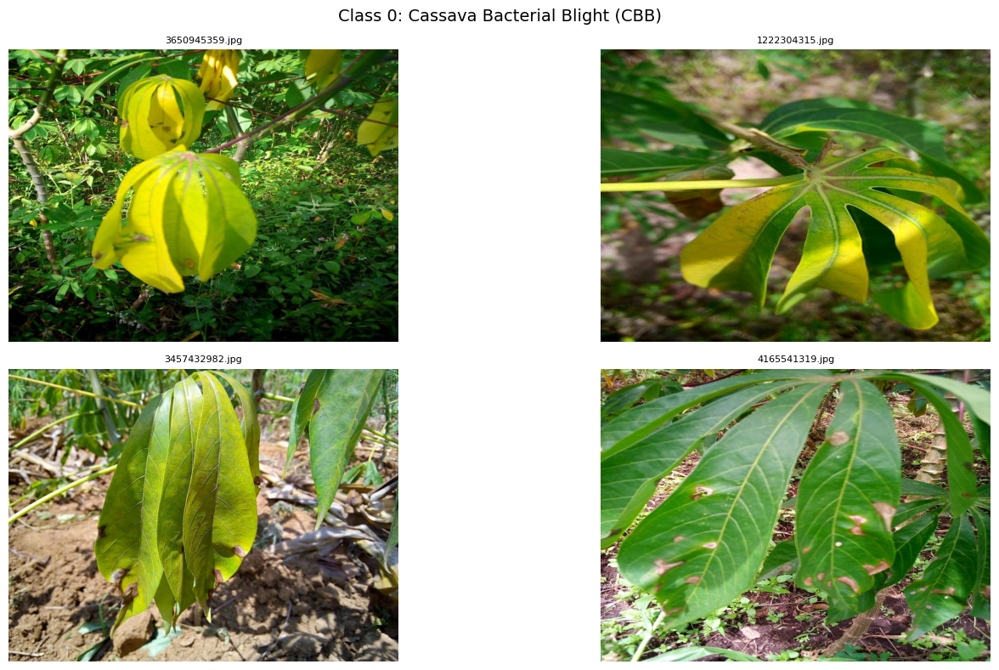

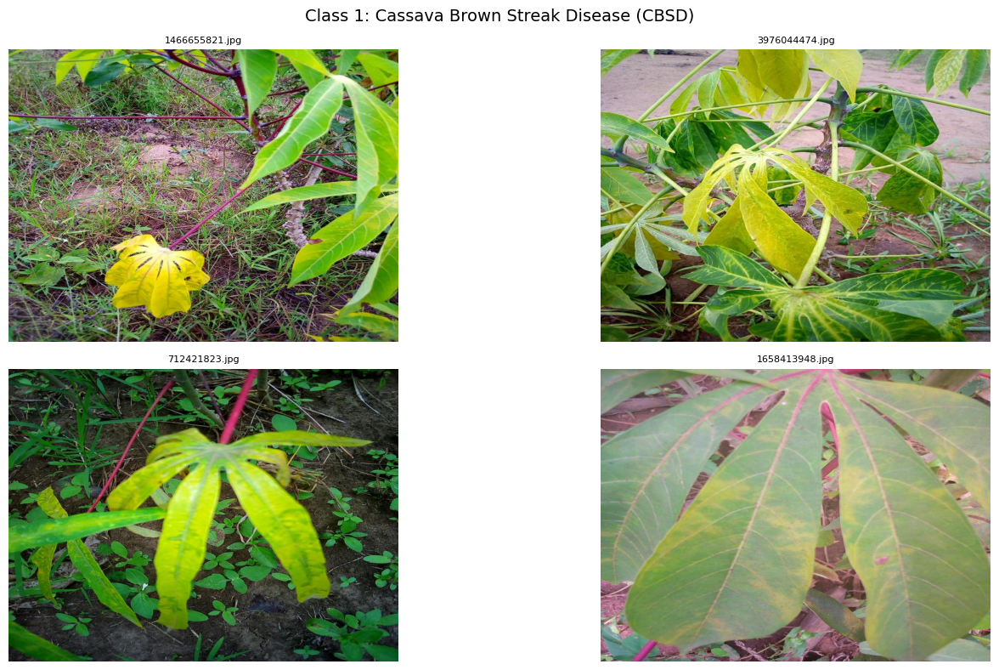

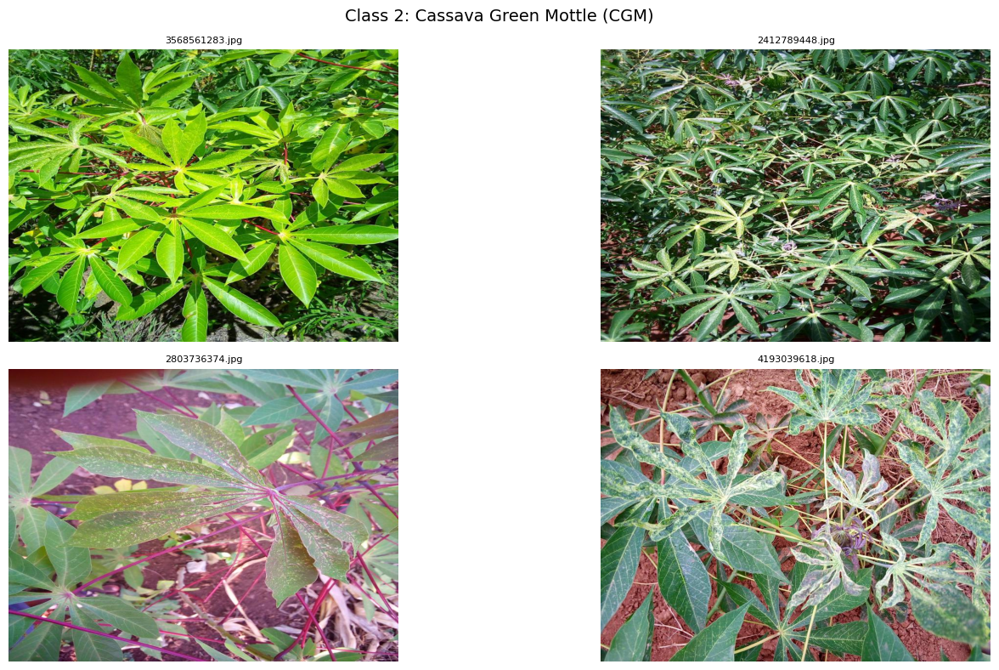

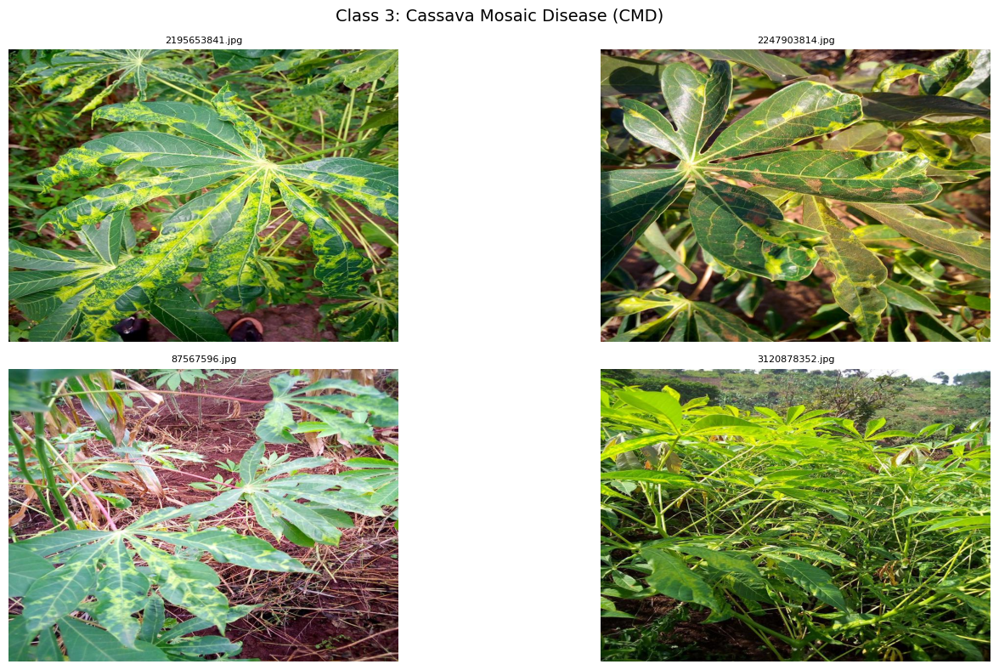

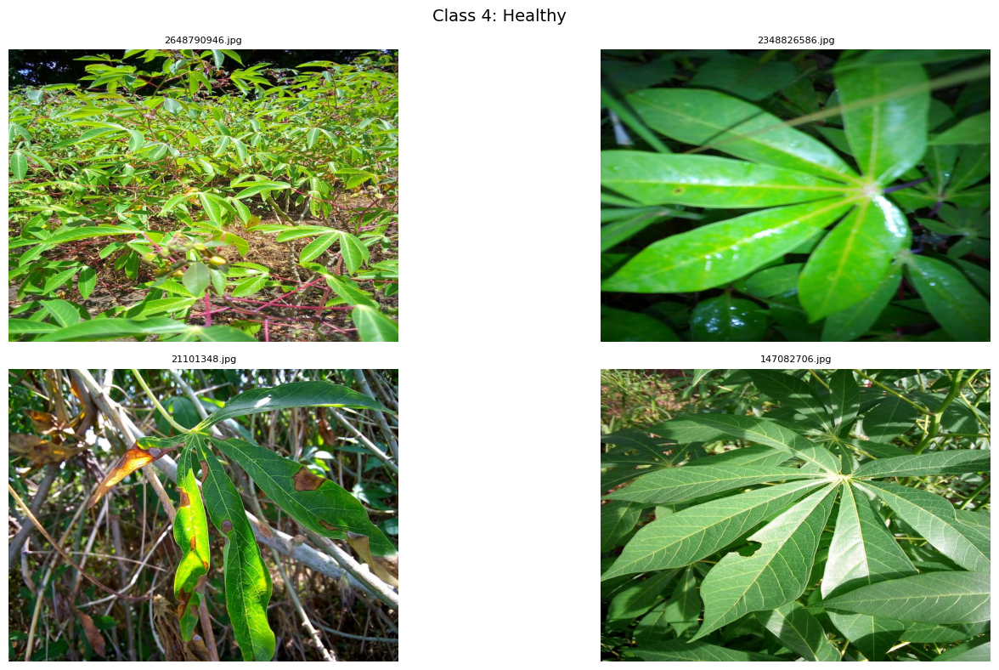

In [6]:
def show_class_samples(class_id, n=8, seed=None):
    """Show n random images of a given class in a 2-row grid."""
    samples = train_df[train_df["label"] == class_id].sample(n, random_state=seed)

    fig, axes = plt.subplots(2, n // 2, figsize=(16, 8))
    for ax, (_, row) in zip(axes.ravel(), samples.iterrows()):
        img = Image.open(os.path.join(DATA_DIR, "train_images", row["image_id"]))
        ax.imshow(img)
        ax.set_title(row["image_id"], fontsize=8)
        ax.axis("off")

    fig.suptitle(f"Class {class_id}: {class_names[str(class_id)]}", fontsize=14)
    plt.tight_layout()
    plt.show()


for class_id in range(num_classes):
    show_class_samples(class_id, n=4, seed=42)

In [7]:
from sklearn.model_selection import train_test_split

# Stratified split keeps the same class proportions in train and validation
train_part, val_part = train_test_split(
    train_df,
    test_size=0.2,
    stratify=train_df["label"],
    random_state=42,
)

# Sanity check: proportions should be almost identical in both parts
print(pd.DataFrame({
    "train": train_part["label"].value_counts(normalize=True).sort_index().round(3),
    "val": val_part["label"].value_counts(normalize=True).sort_index().round(3),
}))

print(f"\nTrain size: {len(train_part)}, Val size: {len(val_part)}")

       train    val
label              
0      0.051  0.051
1      0.102  0.102
2      0.112  0.111
3      0.615  0.615
4      0.120  0.121

Train size: 17117, Val size: 4280


## Step 1: EDA (results)

- All 21,397 training images are exactly 800x600 (4:3), verified on the full set.
- Class 3 (CMD) = 61.5% of data; class 0 (CBB) = 5.1%.
  Majority-class baseline accuracy = 61.5%, which is the number to beat.
- Stratified 80/20 split (17,117 train / 4,280 val); class proportions
  match between the two parts.
- Visual inspection: classes are hard to tell apart by eye and some labels
  look questionable (label noise is a known issue in this dataset).
  Plan: after training a model, inspect confidently wrong predictions
  to check whether these are label errors or genuinely hard cases.

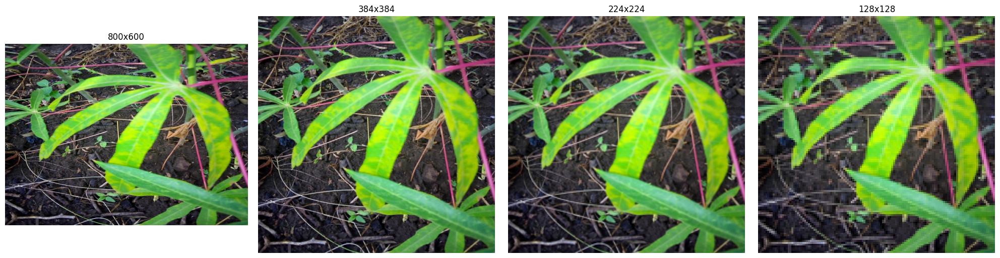

In [8]:
# Compare the same image at different resolutions
# Take an image from class 1 (CBSD) - disease signs are small details
sample = train_df[train_df["label"] == 1].sample(1, random_state=0).iloc[0]
img = Image.open(
    os.path.join(DATA_DIR, "train_images", sample["image_id"])
).convert("RGB")

# Original first, then square sizes that models usually expect
resolutions = [(800, 600), (384, 384), (224, 224), (128, 128)]

fig, axes = plt.subplots(1, len(resolutions), figsize=(20, 5))
for ax, size in zip(axes, resolutions):
    ax.imshow(img.resize(size))
    ax.set_title(f"{size[0]}x{size[1]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Batch shape: torch.Size([32, 3, 224, 224])
Labels: [3, 2, 3, 4, 3, 3, 3, 3, 3, 3]


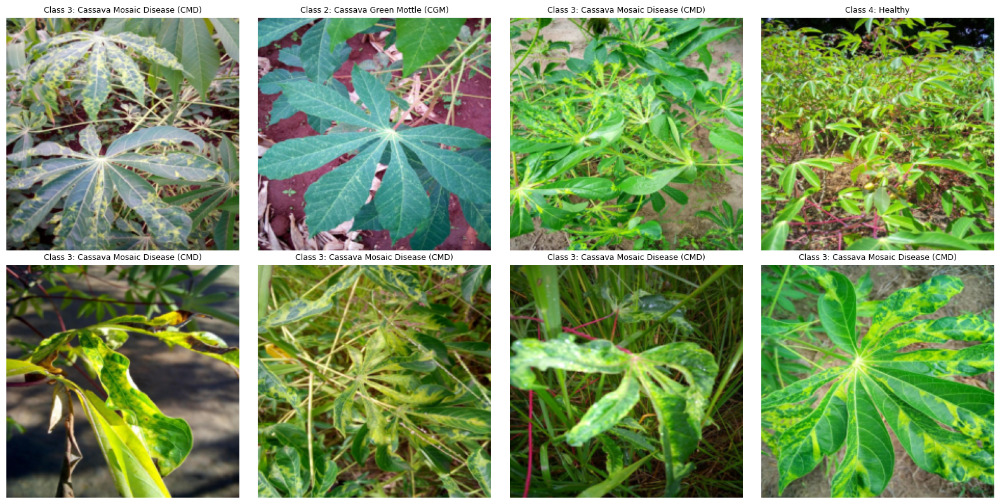

In [9]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

IMG_SIZE = 224
BATCH_SIZE = 32

# Pretrained models expect inputs normalized with ImageNet statistics
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Train: stretch to a square + a light augmentation
train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),  # (height, width)
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Validation: same resize and normalization, but NO random augmentation
val_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class CassavaDataset(Dataset):
    """Reads an image from disk and returns (image_tensor, label)."""

    def __init__(self, df, img_dir, transform):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(os.path.join(self.img_dir, row["image_id"])).convert("RGB")
        return self.transform(img), int(row["label"])


img_dir = os.path.join(DATA_DIR, "train_images")

train_ds = CassavaDataset(train_part, img_dir, train_tfms)
val_ds = CassavaDataset(val_part, img_dir, val_tfms)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Sanity check: look at one batch before training anything
images, labels = next(iter(train_loader))
print("Batch shape:", images.shape)   # expect [32, 3, 224, 224]
print("Labels:", labels[:10].tolist())

# Undo normalization so the images look natural when plotted
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, img, lbl in zip(axes.ravel(), images[:8], labels[:8]):
    ax.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(f"Class {lbl.item()}: {class_names[str(lbl.item())]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 2: Preprocessing decisions

- Images are 800x600; models expect squares, so I stretch to 224x224
  (no cropping: labels apply to the whole image and a lesion near the edge
  could be cut off; no padding: ~25% of pixels would be empty).
- Hypothesis from visual inspection: disease is still visible at 128px.
  Only 224 vs 384 was tested later (see Step 10); 128 was not tested.
- Augmentation: only horizontal flip for the baseline. Validation has no
  random augmentation so the metric is stable.

In [10]:
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Pretrained ResNet18 with a new final layer for our classes
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)


def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += images.size(0)
    return total_loss / total, correct / total


def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            preds = outputs.argmax(1)
            total_loss += loss.item() * images.size(0)
            correct += (preds == labels).sum().item()
            total += images.size(0)
            all_preds += preds.cpu().tolist()
            all_labels += labels.cpu().tolist()
    return total_loss / total, correct / total, all_preds, all_labels


EPOCHS = 3
for epoch in range(EPOCHS):
    tr_loss, tr_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc, val_preds, val_labels = evaluate(model, val_loader)
    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
        f"val loss {val_loss:.3f} acc {val_acc:.3f}"
    )

Device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 187MB/s]


Epoch 1/3 | train loss 0.789 acc 0.713 | val loss 0.740 acc 0.727
Epoch 2/3 | train loss 0.631 acc 0.768 | val loss 0.811 acc 0.710
Epoch 3/3 | train loss 0.576 acc 0.795 | val loss 0.695 acc 0.759


                                     precision    recall  f1-score   support

     Cassava Bacterial Blight (CBB)      0.714     0.069     0.126       217
Cassava Brown Streak Disease (CBSD)      0.612     0.562     0.586       438
         Cassava Green Mottle (CGM)      0.824     0.245     0.378       477
       Cassava Mosaic Disease (CMD)      0.892     0.930     0.911      2632
                            Healthy      0.434     0.818     0.567       516

                           accuracy                          0.759      4280
                          macro avg      0.695     0.525     0.514      4280
                       weighted avg      0.792     0.759     0.737      4280



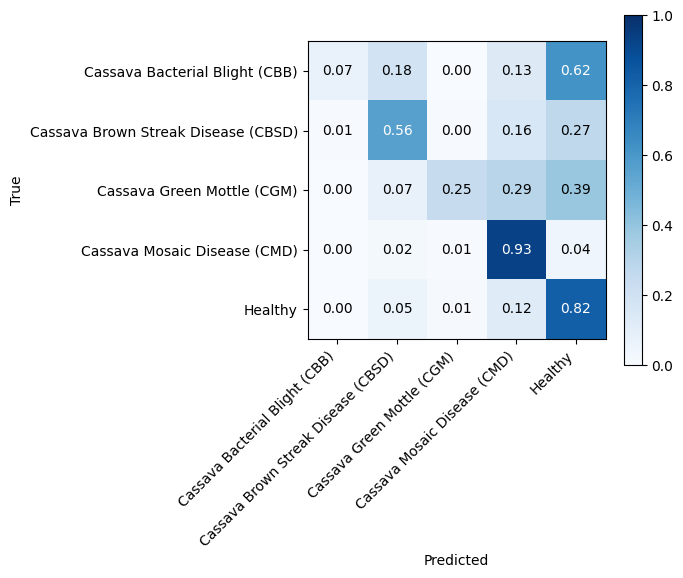

In [11]:
from sklearn.metrics import confusion_matrix, classification_report

names = [class_names[str(i)] for i in range(num_classes)]

# Per-class precision / recall / F1
print(classification_report(val_labels, val_preds, target_names=names, digits=3))

# Row-normalized confusion matrix: each row = true class,
# values show where images of that class were sent by the model
cm = confusion_matrix(val_labels, val_preds, normalize="true")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(num_classes))
ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_yticks(range(num_classes))
ax.set_yticklabels(names)
for i in range(num_classes):
    for j in range(num_classes):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm[i, j] > 0.5 else "black")
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
plt.colorbar(im)
plt.tight_layout()
plt.show()

## Step 3: Error analysis (baseline)

- The model leans heavily toward the majority class: CMD recall is 0.98, but
  46-47% of CBSD and CGM and 32% of CBB images are predicted as CMD.
- CBB is barely recognized: recall 0.13; 29% of CBB is predicted as Healthy
  and 32% as CMD.
- Healthy is confused with every class (29% predicted as CMD), in both directions
  (possible mix of model weakness and label noise).
- Costliest error in practice: diseased plant predicted as Healthy.

In [12]:
from sklearn.metrics import f1_score

EPOCHS = 8
LR = 3e-4

# Fresh model, otherwise training continues from the previous run
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
# Gradually lowers LR to ~0 over training, which smooths val fluctuations
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

for epoch in range(EPOCHS):
    tr_loss, tr_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc, val_preds, val_labels = evaluate(model, val_loader)
    scheduler.step()
    macro_f1 = f1_score(val_labels, val_preds, average="macro")
    print(
        f"Epoch {epoch + 1}/{EPOCHS} | train acc {tr_acc:.3f} | "
        f"val loss {val_loss:.3f} acc {val_acc:.3f} macro-F1 {macro_f1:.3f}"
    )

Epoch 1/8 | train acc 0.765 | val loss 0.564 acc 0.800 macro-F1 0.633
Epoch 2/8 | train acc 0.823 | val loss 0.524 acc 0.810 macro-F1 0.662
Epoch 3/8 | train acc 0.853 | val loss 0.534 acc 0.820 macro-F1 0.681
Epoch 4/8 | train acc 0.884 | val loss 0.514 acc 0.824 macro-F1 0.697
Epoch 5/8 | train acc 0.920 | val loss 0.603 acc 0.822 macro-F1 0.684
Epoch 6/8 | train acc 0.955 | val loss 0.653 acc 0.822 macro-F1 0.684
Epoch 7/8 | train acc 0.977 | val loss 0.647 acc 0.836 macro-F1 0.701
Epoch 8/8 | train acc 0.989 | val loss 0.656 acc 0.831 macro-F1 0.692


## Step 4: Baseline v2

- Changes: lr 0.001 -> 0.0003, 8 epochs, cosine scheduler (changed together).
- Val accuracy 0.725 -> 0.839, macro-F1 0.583 -> 0.712. Val is much more stable.
- New issue: train acc 0.990 vs val acc 0.839, val loss flat after epoch 4.
  The model is overfitting.
- Macro-F1 still well below accuracy, so minority classes remain weak.
- Overfitting and class imbalance are two separate problems with separate fixes.
  Fewer epochs were rejected: val accuracy and macro-F1 still improved until epoch 8.

In [13]:
import numpy as np

# Count training images per class
train_counts = np.bincount(train_part["label"], minlength=num_classes)

# Rare class -> bigger weight
weights = len(train_part) / (num_classes * train_counts)
print("Weights:", weights.round(2))

class_weights = torch.tensor(weights, dtype=torch.float32).to(device)

# Fresh model
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

# The only change compared to v2: weights in the loss
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0003)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=8)

for epoch in range(8):
    tr_loss, tr_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc, val_preds, val_labels = evaluate(model, val_loader)
    scheduler.step()
    macro_f1 = f1_score(val_labels, val_preds, average="macro")
    print(
        f"Epoch {epoch + 1}/8 | train acc {tr_acc:.3f} | "
        f"val loss {val_loss:.3f} acc {val_acc:.3f} macro-F1 {macro_f1:.3f}"
    )

Weights: [3.93 1.96 1.79 0.33 1.66]
Epoch 1/8 | train acc 0.676 | val loss 0.907 acc 0.693 macro-F1 0.574
Epoch 2/8 | train acc 0.763 | val loss 0.959 acc 0.696 macro-F1 0.590
Epoch 3/8 | train acc 0.797 | val loss 0.771 acc 0.794 macro-F1 0.676
Epoch 4/8 | train acc 0.840 | val loss 0.872 acc 0.764 macro-F1 0.650
Epoch 5/8 | train acc 0.880 | val loss 0.852 acc 0.804 macro-F1 0.682
Epoch 6/8 | train acc 0.925 | val loss 1.010 acc 0.819 macro-F1 0.694
Epoch 7/8 | train acc 0.957 | val loss 1.038 acc 0.826 macro-F1 0.706
Epoch 8/8 | train acc 0.969 | val loss 1.051 acc 0.827 macro-F1 0.712


## Step 5: Class weights (v3)

- Same setup as v2, but CrossEntropyLoss with class weights (CBB 3.93 ... CMD 0.33).
- Prediction: macro-F1 up, accuracy down. Result: both down slightly
  (accuracy 0.839 -> 0.825, macro-F1 0.712 -> 0.701).
- Difference is small and likely within run-to-run noise (single run, no fixed seed).
  Conclusion: class weights gave no clear gain here.
- Training was less stable (val accuracy dipped to 0.678 at epoch 4).
- Train/val gap still large (0.972 vs 0.825): weights do not address overfitting.
- Lesson: save per-class results after every run for a fair comparison.
- F1 improved for every class compared to v1, but v1 -> v3 changed many things at once,
  so most of that gain comes from better training settings, not from the weights.

In [14]:
# Stronger augmentation for training only; validation stays unchanged
train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),  # no hue change: color is a disease sign
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Rebuild the training dataset and loader so they use the new transforms
train_ds = CassavaDataset(train_part, img_dir, train_tfms)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

torch.manual_seed(42)  # fixed seed for a fairer comparison

# Everything else is the same as v3: class weights, learning rate 0.0003, 8 epochs
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0003)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=8)

for epoch in range(8):
    tr_loss, tr_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc, val_preds, val_labels = evaluate(model, val_loader)
    scheduler.step()
    macro_f1 = f1_score(val_labels, val_preds, average="macro")
    print(
        f"Epoch {epoch + 1}/8 | train acc {tr_acc:.3f} | "
        f"val loss {val_loss:.3f} acc {val_acc:.3f} macro-F1 {macro_f1:.3f}"
    )

# Print the per-class report right away, so the results are not lost
print(classification_report(val_labels, val_preds, target_names=names, digits=3))

Epoch 1/8 | train acc 0.636 | val loss 1.126 acc 0.454 macro-F1 0.433
Epoch 2/8 | train acc 0.727 | val loss 0.822 acc 0.714 macro-F1 0.613
Epoch 3/8 | train acc 0.752 | val loss 0.819 acc 0.724 macro-F1 0.619
Epoch 4/8 | train acc 0.776 | val loss 0.941 acc 0.652 macro-F1 0.561
Epoch 5/8 | train acc 0.790 | val loss 0.759 acc 0.784 macro-F1 0.674
Epoch 6/8 | train acc 0.809 | val loss 0.749 acc 0.786 macro-F1 0.674
Epoch 7/8 | train acc 0.830 | val loss 0.707 acc 0.816 macro-F1 0.711
Epoch 8/8 | train acc 0.843 | val loss 0.696 acc 0.811 macro-F1 0.714
                                     precision    recall  f1-score   support

     Cassava Bacterial Blight (CBB)      0.517     0.710     0.598       217
Cassava Brown Streak Disease (CBSD)      0.712     0.717     0.714       438
         Cassava Green Mottle (CGM)      0.644     0.761     0.697       477
       Cassava Mosaic Disease (CMD)      0.968     0.863     0.913      2632
                            Healthy      0.587     0.7

## Step 6: Stronger augmentation (v4)

- Added vertical flip, rotation (20 deg), brightness/contrast jitter (no hue).
- Train/val gap dropped from 14.7 to 3.6 points (train 0.843, val 0.807):
  overfitting is fixed.
- Val metrics did not improve: accuracy 0.825 -> 0.807, macro-F1 0.701 -> 0.708.
  Differences are small, single run each, so not conclusive.
- CBB recall 0.535 -> 0.737 with precision unchanged (~0.50); CMD recall
  0.918 -> 0.862.
- Train and val still rising at epoch 8, so the model is probably undertrained
  with augmentation. Next: 15 epochs, nothing else changed.

In [15]:
torch.manual_seed(42)
EPOCHS = 15

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0003)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

for epoch in range(EPOCHS):
    tr_loss, tr_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc, val_preds, val_labels = evaluate(model, val_loader)
    scheduler.step()
    macro_f1 = f1_score(val_labels, val_preds, average="macro")
    print(
        f"Epoch {epoch + 1}/{EPOCHS} | train acc {tr_acc:.3f} | "
        f"val loss {val_loss:.3f} acc {val_acc:.3f} macro-F1 {macro_f1:.3f}"
    )

print(classification_report(val_labels, val_preds, target_names=names, digits=3))

# Keep per-class results so later runs can be compared fairly
all_results = {}
all_results["v5_aug_15epochs"] = classification_report(
    val_labels, val_preds, target_names=names, output_dict=True
)

Epoch 1/15 | train acc 0.641 | val loss 1.140 acc 0.491 macro-F1 0.462
Epoch 2/15 | train acc 0.725 | val loss 0.855 acc 0.686 macro-F1 0.592
Epoch 3/15 | train acc 0.747 | val loss 0.844 acc 0.746 macro-F1 0.621
Epoch 4/15 | train acc 0.763 | val loss 0.960 acc 0.641 macro-F1 0.554
Epoch 5/15 | train acc 0.775 | val loss 0.862 acc 0.756 macro-F1 0.626
Epoch 6/15 | train acc 0.782 | val loss 0.830 acc 0.723 macro-F1 0.619
Epoch 7/15 | train acc 0.798 | val loss 0.732 acc 0.795 macro-F1 0.684
Epoch 8/15 | train acc 0.807 | val loss 0.810 acc 0.768 macro-F1 0.664
Epoch 9/15 | train acc 0.819 | val loss 0.712 acc 0.788 macro-F1 0.694
Epoch 10/15 | train acc 0.837 | val loss 0.784 acc 0.789 macro-F1 0.687
Epoch 11/15 | train acc 0.846 | val loss 0.729 acc 0.812 macro-F1 0.716
Epoch 12/15 | train acc 0.861 | val loss 0.717 acc 0.818 macro-F1 0.721
Epoch 13/15 | train acc 0.870 | val loss 0.741 acc 0.819 macro-F1 0.719
Epoch 14/15 | train acc 0.875 | val loss 0.764 acc 0.827 macro-F1 0.725
E

## Step 7: More epochs (v5)

- 15 epochs instead of 8, everything else as v4. Prediction: val accuracy
  above 0.825. Result: 0.817, so no.
- Macro-F1 0.708 -> 0.717, accuracy 0.807 -> 0.817. Small, within run noise.
- Plateau from about epoch 9. Train/val gap 5.9 points (v3 had 14.7).
- v2 still has the best accuracy (0.839); later changes fixed overfitting
  and raised rare-class recall but did not clearly improve the metrics.
- Next: inspect confidently wrong predictions
  to check the label-noise hypothesis.

In [16]:
import torch.nn.functional as F

# Run the current model (v5) on validation and keep the confidence of each prediction
model.eval()
probs = []
with torch.no_grad():
    for images, _ in val_loader:
        probs.append(F.softmax(model(images.to(device)), dim=1).cpu())
probs = torch.cat(probs)

val_results = val_part.reset_index(drop=True).copy()
val_results["pred"] = probs.argmax(1).numpy()
val_results["confidence"] = probs.max(1).values.numpy()
wrong = val_results[val_results["pred"] != val_results["label"]]

short_names = ["CBB", "CBSD", "CGM", "CMD", "Healthy"]
print("Wrong predictions:", len(wrong), "of", len(val_results))

Wrong predictions: 751 of 4280


CBB: 68 errors in total
CBSD: 117 errors in total
CGM: 119 errors in total
CMD: 298 errors in total
Healthy: 149 errors in total


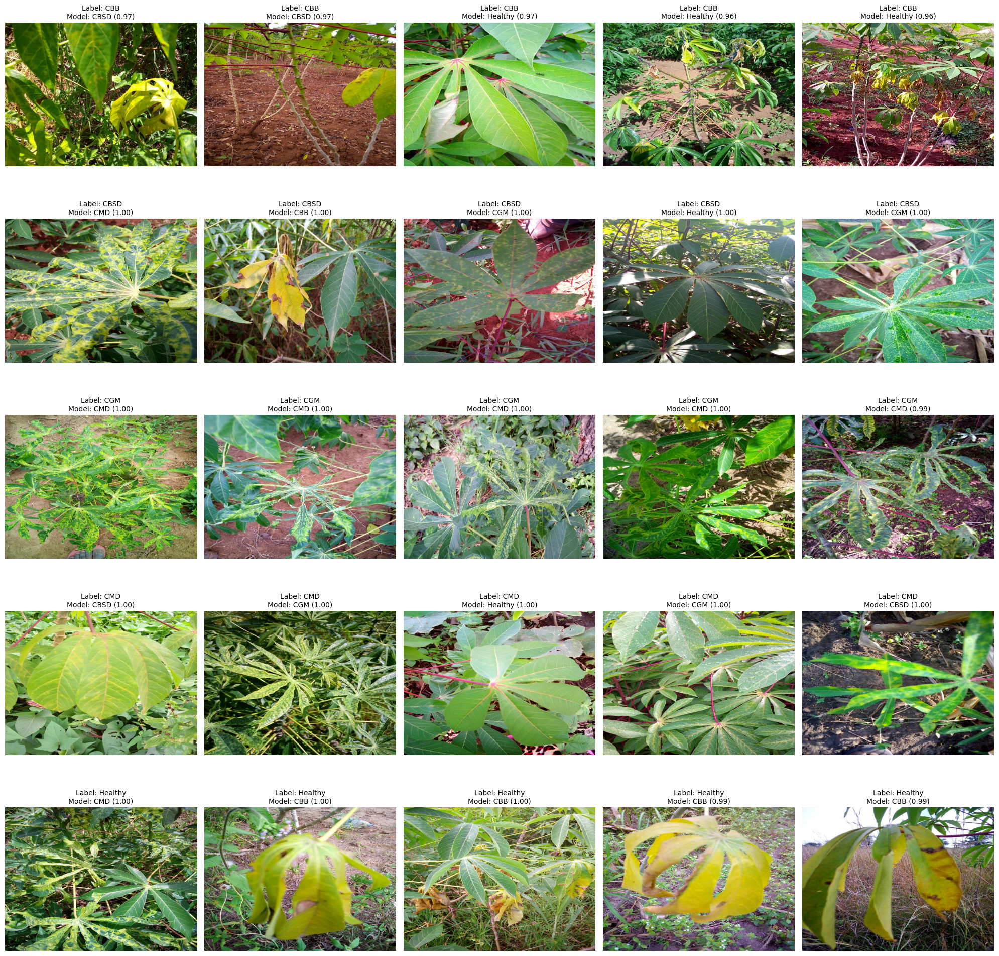

In [17]:
def show_confident_errors_per_class(wrong_df, n_per_class=5):
    """One row per true class: the n most confident wrong predictions."""
    num_rows = len(short_names)
    fig, axes = plt.subplots(
        num_rows, n_per_class, figsize=(4 * n_per_class, 4 * num_rows), squeeze=False
    )

    for class_id in range(num_rows):
        errors = (
            wrong_df[wrong_df["label"] == class_id]
            .sort_values("confidence", ascending=False)
            .head(n_per_class)
        )
        print(f"{short_names[class_id]}: {(wrong_df['label'] == class_id).sum()} errors in total")

        for j in range(n_per_class):
            ax = axes[class_id, j]
            ax.axis("off")
            if j < len(errors):
                row = errors.iloc[j]
                img = Image.open(os.path.join(img_dir, row["image_id"]))
                ax.imshow(img)
                ax.set_title(
                    f"Label: {short_names[row['label']]}\n"
                    f"Model: {short_names[row['pred']]} ({row['confidence']:.2f})",
                    fontsize=10,
                )

    plt.tight_layout()
    plt.show()


show_confident_errors_per_class(wrong, n_per_class=5)

In [18]:
# Label says Healthy, model says a disease
healthy_wrong = wrong[wrong["label"] == 4]
print("Healthy label, model says disease:", len(healthy_wrong))
print("  with confidence above 0.9:", (healthy_wrong["confidence"] > 0.9).sum())
print(healthy_wrong["pred"].map(lambda i: short_names[i]).value_counts())

# The opposite direction: label says a disease, model says Healthy
missed = wrong[(wrong["label"] != 4) & (wrong["pred"] == 4)]
print("\nDisease label, model says Healthy:", len(missed))
print("  with confidence above 0.9:", (missed["confidence"] > 0.9).sum())

Healthy label, model says disease: 149
  with confidence above 0.9: 39
pred
CBB     62
CGM     32
CBSD    29
CMD     26
Name: count, dtype: int64

Disease label, model says Healthy: 230
  with confidence above 0.9: 44


## Step 8: Label noise (v5)

- "Noisy labels" means that some labels are wrong (not blurry images). Known property of this dataset.
- Several confident "errors" have the label Healthy while the leaf looks diseased to the eye
  (my judgment, not an expert's). The model is probably right there, so validation scores are underestimated.
- Counts: 149 Healthy-labeled images predicted as a disease, 232 diseased images predicted as Healthy.
  Only 76 are confident (above 0.9) disagreements, less than 2% of validation,
  so label noise alone does not explain the errors.
- Concern: class weights multiply the penalty on rare classes, so wrong labels there are fitted harder.
  Tested next by removing the weights (v6).

In [19]:
torch.manual_seed(42)
EPOCHS = 15

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

criterion = nn.CrossEntropyLoss()  # no class weights, the only change compared to v5
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0003)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

for epoch in range(EPOCHS):
    tr_loss, tr_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc, val_preds, val_labels = evaluate(model, val_loader)
    scheduler.step()
    macro_f1 = f1_score(val_labels, val_preds, average="macro")
    print(
        f"Epoch {epoch + 1}/{EPOCHS} | train acc {tr_acc:.3f} | "
        f"val loss {val_loss:.3f} acc {val_acc:.3f} macro-F1 {macro_f1:.3f}"
    )

print(classification_report(val_labels, val_preds, target_names=names, digits=3))

# Keep per-class results so later runs can be compared fairly
all_results["v6_no_weights"] = classification_report(
    val_labels, val_preds, target_names=names, output_dict=True
)

Epoch 1/15 | train acc 0.744 | val loss 0.802 acc 0.706 macro-F1 0.598
Epoch 2/15 | train acc 0.796 | val loss 0.563 acc 0.796 macro-F1 0.653
Epoch 3/15 | train acc 0.807 | val loss 0.563 acc 0.799 macro-F1 0.650
Epoch 4/15 | train acc 0.819 | val loss 0.552 acc 0.804 macro-F1 0.658
Epoch 5/15 | train acc 0.830 | val loss 0.515 acc 0.813 macro-F1 0.679
Epoch 6/15 | train acc 0.839 | val loss 0.632 acc 0.765 macro-F1 0.593
Epoch 7/15 | train acc 0.850 | val loss 0.516 acc 0.821 macro-F1 0.696
Epoch 8/15 | train acc 0.858 | val loss 0.485 acc 0.829 macro-F1 0.695
Epoch 9/15 | train acc 0.864 | val loss 0.479 acc 0.832 macro-F1 0.706
Epoch 10/15 | train acc 0.879 | val loss 0.457 acc 0.841 macro-F1 0.707
Epoch 11/15 | train acc 0.886 | val loss 0.458 acc 0.848 macro-F1 0.735
Epoch 12/15 | train acc 0.896 | val loss 0.458 acc 0.845 macro-F1 0.733
Epoch 13/15 | train acc 0.906 | val loss 0.465 acc 0.848 macro-F1 0.731
Epoch 14/15 | train acc 0.907 | val loss 0.468 acc 0.850 macro-F1 0.733
E

In [20]:
from sklearn.metrics import confusion_matrix

# Save the current best model
torch.save(model.state_dict(), "v6_resnet18.pth")

cm = confusion_matrix(val_labels, val_preds)
print("Healthy label, predicted CBB:", cm[4, 0])           # was 61 in v5
print("Disease label, predicted Healthy:", cm[:4, 4].sum())  # was 232 in v5

Healthy label, predicted CBB: 44
Disease label, predicted Healthy: 213


## Step 9: Removing class weights (v6)

- v5 without class weights, everything else identical.
  Accuracy 0.817 -> 0.852, macro-F1 0.717 -> 0.738 (single run).
- Healthy images predicted as CBB: 61 -> 43. Diseased images predicted as Healthy: 232 -> 204.
- But it is a trade-off: recall of the rare disease classes dropped
  (CBB 0.691 -> 0.581, CBSD 0.726 -> 0.687, CGM 0.746 -> 0.711), while precision rose.
  The overall gain comes mostly from the big class CMD.

In [21]:
IMG_SIZE = 384

train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Validation must use the same size, only without random augmentation
val_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_ds = CassavaDataset(train_part, img_dir, train_tfms)
val_ds = CassavaDataset(val_part, img_dir, val_tfms)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

torch.manual_seed(42)
EPOCHS = 15

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

criterion = nn.CrossEntropyLoss()  # no class weights, same as v6
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0003)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = []

for epoch in range(EPOCHS):
    tr_loss, tr_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc, val_preds, val_labels = evaluate(model, val_loader)
    scheduler.step()
    macro_f1 = f1_score(val_labels, val_preds, average="macro")
    history.append({"epoch": epoch + 1, "train_loss": tr_loss, "train_acc": tr_acc,
                    "val_loss": val_loss, "val_acc": val_acc, "val_macro_f1": macro_f1})
    print(
        f"Epoch {epoch + 1}/{EPOCHS} | train acc {tr_acc:.3f} | "
        f"val loss {val_loss:.3f} acc {val_acc:.3f} macro-F1 {macro_f1:.3f}"
    )

pd.DataFrame(history).to_csv("v7_history.csv", index=False)
print(classification_report(val_labels, val_preds, target_names=names, digits=3))

all_results["v7_384px"] = classification_report(
    val_labels, val_preds, target_names=names, output_dict=True
)
torch.save(model.state_dict(), "v7_resnet18_384.pth")

cm = confusion_matrix(val_labels, val_preds)
print("Healthy label, predicted CBB:", cm[4, 0])           # v6: 43
print("Disease label, predicted Healthy:", cm[:4, 4].sum())  # v6: 204

Epoch 1/15 | train acc 0.790 | val loss 0.592 acc 0.789 macro-F1 0.670
Epoch 2/15 | train acc 0.828 | val loss 0.526 acc 0.821 macro-F1 0.686
Epoch 3/15 | train acc 0.842 | val loss 0.546 acc 0.818 macro-F1 0.681
Epoch 4/15 | train acc 0.851 | val loss 0.477 acc 0.839 macro-F1 0.719
Epoch 5/15 | train acc 0.860 | val loss 0.464 acc 0.844 macro-F1 0.720
Epoch 6/15 | train acc 0.866 | val loss 0.435 acc 0.848 macro-F1 0.700
Epoch 7/15 | train acc 0.875 | val loss 0.418 acc 0.856 macro-F1 0.746
Epoch 8/15 | train acc 0.880 | val loss 0.504 acc 0.826 macro-F1 0.698
Epoch 9/15 | train acc 0.888 | val loss 0.403 acc 0.864 macro-F1 0.755
Epoch 10/15 | train acc 0.898 | val loss 0.399 acc 0.866 macro-F1 0.748
Epoch 11/15 | train acc 0.906 | val loss 0.413 acc 0.867 macro-F1 0.764
Epoch 12/15 | train acc 0.913 | val loss 0.420 acc 0.864 macro-F1 0.758
Epoch 13/15 | train acc 0.920 | val loss 0.410 acc 0.873 macro-F1 0.767
Epoch 14/15 | train acc 0.925 | val loss 0.418 acc 0.873 macro-F1 0.767
E

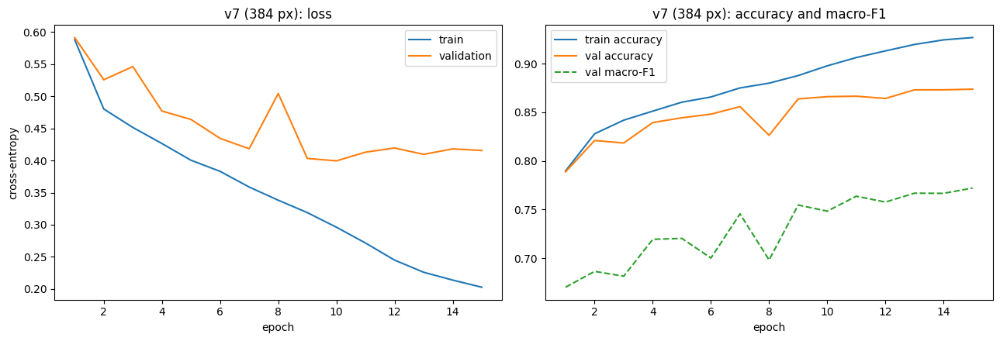

In [22]:
hist = pd.read_csv("v7_history.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hist.epoch, hist.train_loss, label="train")
axes[0].plot(hist.epoch, hist.val_loss, label="validation")
axes[0].set(title="v7 (384 px): loss", xlabel="epoch", ylabel="cross-entropy")
axes[0].legend()
axes[1].plot(hist.epoch, hist.train_acc, label="train accuracy")
axes[1].plot(hist.epoch, hist.val_acc, label="val accuracy")
axes[1].plot(hist.epoch, hist.val_macro_f1, label="val macro-F1", linestyle="--")
axes[1].set(title="v7 (384 px): accuracy and macro-F1", xlabel="epoch")
axes[1].legend()
plt.tight_layout()
plt.savefig("v7_curves.png", dpi=120)
plt.show()

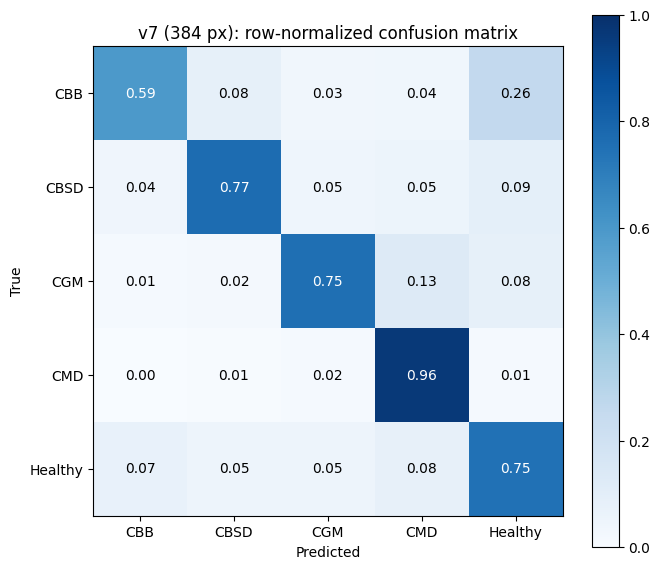

In [23]:
cm = confusion_matrix(val_labels, val_preds, normalize="true")  # v7, last epoch

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(num_classes)); ax.set_xticklabels(short_names)
ax.set_yticks(range(num_classes)); ax.set_yticklabels(short_names)
for i in range(num_classes):
    for j in range(num_classes):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm[i, j] > 0.5 else "black")
ax.set(xlabel="Predicted", ylabel="True", title="v7 (384 px): row-normalized confusion matrix")
plt.colorbar(im)
plt.tight_layout()
plt.savefig("v7_confusion_matrix.png", dpi=120)
plt.show()

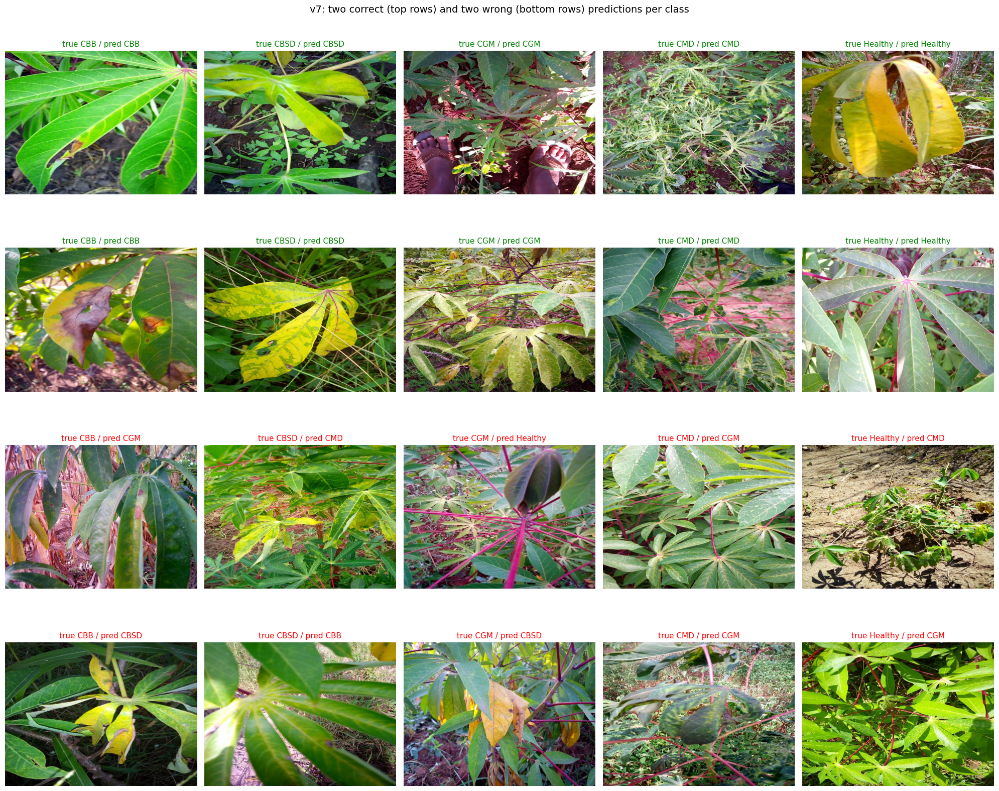

In [24]:
# Two correct and two wrong v7 predictions per class (last epoch), for a visual impression
val_view = val_part.reset_index(drop=True).assign(pred=val_preds)
rng = np.random.default_rng(SEED)
N_EACH = 2

fig, axes = plt.subplots(2 * N_EACH, num_classes, figsize=(4 * num_classes, 4.2 * 2 * N_EACH))
for c in range(num_classes):
    of_class = val_view[val_view.label == c]
    groups = [(of_class[of_class.pred == c], "green", 0), (of_class[of_class.pred != c], "red", N_EACH)]
    for subset, color, first_row in groups:
        picks = rng.choice(len(subset), size=min(N_EACH, len(subset)), replace=False)
        for k in range(N_EACH):
            ax = axes[first_row + k, c]
            ax.axis("off")
            if k >= len(picks):
                continue
            r = subset.iloc[picks[k]]
            ax.imshow(Image.open(os.path.join(img_dir, r.image_id)))
            ax.set_title(f"true {short_names[c]} / pred {short_names[r.pred]}", color=color, fontsize=11)
plt.suptitle("v7: two correct (top rows) and two wrong (bottom rows) predictions per class", fontsize=14)
plt.tight_layout()
plt.savefig("v7_examples.png", dpi=100)
plt.show()

## Step 10: Resolution 384 (v7)

- v7 = v6 with 384x384 instead of 224x224 (train and validation).
- Prediction: results will improve, because small disease details
  (spots, streaks) are less blurred at higher resolution.
- Compare with v6: accuracy 0.852, macro-F1 0.738,
  disease -> Healthy errors 204.
- Result: accuracy 0.852 -> 0.872, macro-F1 0.738 -> 0.766. The prediction held.
- F1 improved for all 5 classes (CBSD 0.740 -> 0.785, CGM 0.740 -> 0.781,
  Healthy 0.678 -> 0.705, CMD 0.946 -> 0.956, CBB 0.586 -> 0.600).
- Diseased images predicted as Healthy: 204 -> 166. Healthy images predicted as CBB: 43 -> 47 (no real change).
- CBB is still the weakest class: higher resolution barely helped it.
- Cost: about 3x more pixels per image, so training is much slower. Single run,
  but the gain is larger than the ~0.01 differences seen earlier.

In [25]:
rows = {}
for name, r in all_results.items():
    rows[name] = {"Accuracy": r["accuracy"], "Macro-F1": r["macro avg"]["f1-score"],
                  **{f"F1 {s}": r[n]["f1-score"] for s, n in zip(short_names, names)}}

summary = pd.DataFrame(rows).T.round(3)
summary.to_csv("results.csv")
print(summary.to_string())

                 Accuracy  Macro-F1  F1 CBB  F1 CBSD  F1 CGM  F1 CMD  F1 Healthy
v5_aug_15epochs     0.825     0.723   0.598    0.739   0.692   0.925       0.659
v6_no_weights       0.850     0.736   0.591    0.748   0.724   0.945       0.672
v7_384px            0.874     0.772   0.617    0.794   0.774   0.955       0.720
